<a href="https://colab.research.google.com/github/Aleeza-Nadeem/flyrank-ml-internship-starter/blob/main/work/notebooks/w04_signal_audit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ML-06 — Signal Audit: Do the Flags Hold?

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Aleeza-Nadeem/flyrank-ml-internship-starter/blob/main/work/notebooks/w04_signal_audit.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Distributions

*Look before deciding: distributions of your key fields. Note the heavy tails.*

**What I look at first:** the key fields (impressions, clicks, CTR, position, word count) before any test. Search data is heavy-tailed and full of zeros, so a mean can mislead; I report percentiles, the share of zeros, and the mean-to-median ratio. All values here are from the previous 30 days unless a test says otherwise. Rows missing key fields or with zero previous impressions are dropped.

rows used: 26612 of 30000 | clients: 31


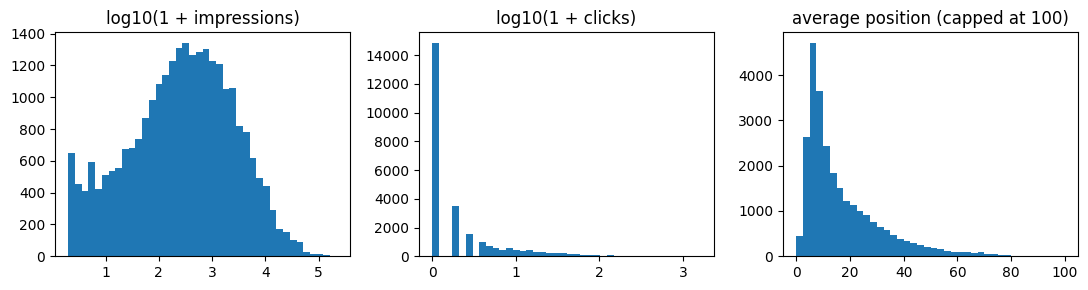

,field,n,zeros_pct,p10,median,p90,p99,max,mean_over_median
0,impressions_prev_30d,26612,0.0,8.0,305.5,4574.6000,28319.8600,218786.0,6.58
1,clicks_prev_30d,26612,55.8,0.0,0.0,12.0000,97.8900,1627.0,NaN
2,ctr_prev,26612,55.8,0.0,0.0,0.0065,0.0408,1.0,NaN
3,avg_position,26612,0.0,4.7,11.8,37.1000,68.0000,138.8,1.45
4,word_count,19167,0.0,1473.0,2900.0,5557.4000,7373.6800,9546.0,1.11


In [5]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/FlyRank/internship-starter/resolve/main/content_refresh_anonymized.csv"
df = pd.read_csv(url)
need = ["clicks_last_30d", "impressions_prev_30d", "clicks_prev_30d", "sessions_prev_30d", "avg_position", "client_id"]
d = df.dropna(subset=need).copy()
d = d[d.impressions_prev_30d > 0].reset_index(drop=True)
d["ctr_prev"] = d.clicks_prev_30d / d.impressions_prev_30d
print("rows used:", len(d), "of", len(df), "| clients:", d.client_id.nunique())

fields = {"impressions_prev_30d": d.impressions_prev_30d, "clicks_prev_30d": d.clicks_prev_30d,
          "ctr_prev": d.ctr_prev, "avg_position": d.avg_position, "word_count": d.word_count}
rows = []
for k, v in fields.items():
    v = v.dropna()
    med = v.median()
    rows.append({"field": k, "n": len(v), "zeros_pct": round((v == 0).mean() * 100, 1),
                 "p10": round(v.quantile(.10), 4), "median": round(med, 4), "p90": round(v.quantile(.90), 4),
                 "p99": round(v.quantile(.99), 4), "max": round(v.max(), 4),
                 "mean_over_median": round(v.mean() / med, 2) if med > 0 else np.nan})
dist = pd.DataFrame(rows)

fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].hist(np.log10(1 + d.impressions_prev_30d), bins=40); ax[0].set_title("log10(1 + impressions)")
ax[1].hist(np.log10(1 + d.clicks_prev_30d), bins=40); ax[1].set_title("log10(1 + clicks)")
ax[2].hist(d.avg_position.clip(upper=100), bins=40); ax[2].set_title("average position (capped at 100)")
plt.tight_layout(); plt.show()
dist


## 2. Signal test #1 / #2 / #3 (verdict each)

*Three safe signals, each with a mini-test and a verdict: CONFIRMED / OPPOSITE / MIXED / FALSE.*

Three safe signals, each a plain claim with an expected direction. I use Spearman rank correlation (it copes with heavy tails) and also repeat the test inside each client with at least 100 pages, so one big client cannot decide the answer.

| # | Claim | Expected | Pair tested |
|---|---|---|---|
| 1 | Closer to the top of the results means a higher CTR | negative | average position vs CTR |
| 2 | Recently updated pages grow more | negative | days since last update vs change in clicks (next 30 days vs previous 30) |
| 3 | Longer pages earn more clicks | positive | word count vs previous clicks |

**Verdict rule (set before looking):** CONFIRMED if the overall correlation points the expected way, is at least 0.10 in size, and at least 70% of clients agree. OPPOSITE if it points the other way, is at least 0.10 in size, and at most 30% of clients agree with the expected direction. FALSE if the size is under 0.05. MIXED for everything else. Signal 2 uses next-30-day clicks only to test a claim, never as a model feature. These are associations, not causes.

In [6]:
def audit(name, x, y, expected_sign, min_pages=100):
    ok = x.notna() & y.notna()
    rho = x[ok].corr(y[ok], method="spearman")
    agree = []
    for cid, g in d[ok].groupby("client_id"):
        if len(g) >= min_pages:
            r = x[ok].loc[g.index].corr(y[ok].loc[g.index], method="spearman")
            if pd.notna(r): agree.append(np.sign(r) == expected_sign)
    share = float(np.mean(agree)) if agree else np.nan
    same_way = np.sign(rho) == expected_sign
    if abs(rho) < 0.05: verdict = "FALSE"
    elif abs(rho) >= 0.10 and same_way and share >= 0.70: verdict = "CONFIRMED"
    elif abs(rho) >= 0.10 and (not same_way) and share <= 0.30: verdict = "OPPOSITE"
    else: verdict = "MIXED"
    return {"signal": name, "spearman_rho": round(rho, 3), "clients_tested": len(agree),
            "clients_agreeing_pct": round(share * 100, 1) if agree else np.nan, "verdict": verdict}

growth = np.log1p(d.clicks_last_30d) - np.log1p(d.clicks_prev_30d)
results = pd.DataFrame([
    audit("1. closer to top -> higher CTR", d.avg_position, d.ctr_prev, -1),
    audit("2. recently updated -> grows more", d.days_since_last_update, growth, -1),
    audit("3. longer page -> more clicks", d.word_count, d.clicks_prev_30d, +1)])
results


,signal,spearman_rho,clients_tested,clients_agreeing_pct,verdict
0,1. closer to top -> higher CTR,-0.260,21,90.5,CONFIRMED
1,2. recently updated -> grows more,0.015,21,57.1,FALSE
2,3. longer page -> more clicks,0.184,19,63.2,MIXED


## 3. The flag-linked test

*Pick a signal one of FlyRank's real flags relies on. Does the data support the rule's assumption?*

**The signal I picked:** FlyRank-style "under-clicked" (fix CTR) flags assume two things: that a page's CTR can be compared with a *typical* CTR for its position, and that a CTR below typical points to a fixable snippet problem. I can test the first half with data: is there a stable typical CTR per position bucket? I check the weighted CTR (total clicks over total impressions, so big pages count more), the median page, the share of pages with zero clicks, and whether the buckets fall in the expected order. I cannot test the second half (that a rewrite fixes it) without an experiment, so I do not claim it.

I also compare any flag-like columns in the release with page visibility, because a flag can only fire where there is enough data to diagnose a page. This is descriptive only.

In [7]:
d["pos_bucket"] = pd.cut(d.avg_position, [0, 3, 5, 10, 20, 1000], labels=["1-3", "3-5", "5-10", "10-20", "20+"])
g = d.groupby("pos_bucket", observed=True).agg(
    pages=("ctr_prev", "size"), median_ctr=("ctr_prev", "median"),
    zero_click_pct=("clicks_prev_30d", lambda s: round((s == 0).mean() * 100, 1)),
    clicks=("clicks_prev_30d", "sum"), impressions=("impressions_prev_30d", "sum"))
g["weighted_ctr"] = g.clicks / g.impressions
g = g.drop(columns=["clicks", "impressions"]).round(5)
print("weighted CTR falls bucket by bucket:", bool(g.weighted_ctr.is_monotonic_decreasing))
print("median CTR falls bucket by bucket:  ", bool(g.median_ctr.is_monotonic_decreasing))
display(g) if "display" in globals() else print(g)

# flag-like columns (names only): are flagged pages more or less visible?
flag_cols = [c for c in df.columns if c.startswith(("needs_", "is_")) or "flag" in c][:8]
frows = []
for c in flag_cols:
    flagged = d[c].astype(str).str.lower().isin(["true", "1", "1.0", "yes"]) if c in d.columns else None
    if flagged is not None and 0 < flagged.sum() < len(d):
        frows.append({"flag": c, "flagged_pages": int(flagged.sum()), "flagged_pct": round(flagged.mean() * 100, 1),
                      "median_impressions_flagged": d.loc[flagged, "impressions_prev_30d"].median(),
                      "median_impressions_unflagged": d.loc[~flagged, "impressions_prev_30d"].median()})
flags_table = pd.DataFrame(frows) if frows else pd.DataFrame({"note": ["no flag-like columns found in this release"]})
flags_table


weighted CTR falls bucket by bucket: False
median CTR falls bucket by bucket:   False
            pages  median_ctr  zero_click_pct  weighted_ctr
pos_bucket                                                 
1-3           809     0.00000            54.4       0.00557
3-5          2456     0.00207            36.8       0.00459
5-10         8306     0.00066            46.4       0.00277
10-20        6958     0.00000            57.8       0.00349
20+          8075     0.00000            69.6       0.00142


,flag,flagged_pages,flagged_pct,median_impressions_flagged,median_impressions_unflagged
0,is_quick_win,6802,25.6,420.5,254.5
1,needs_ctr_fix,535,2.0,2540.0,289.0
2,needs_engagement_fix,8866,33.3,2040.5,116.0
3,is_underperformer,5656,21.3,10.0,578.0
4,is_declining,5563,20.9,1626.0,163.0
5,is_initial_refresh_candidate,11259,42.3,582.0,129.0


## 4. What this means in practice

Last month's visibility carries most of the usable signal, so a content team should start with pages that already have impressions and clicks. A "typical CTR for this position" benchmark is only a rough cue here, because many pages have zero clicks and the medians are near zero, so an under-clicked flag should prompt a person to look at the page, not decide for them. Treat every flag and benchmark as decision support for a human reviewer. The three signal verdicts above are associations in this sample and do not show that a change causes more clicks.

In [8]:
summary = results[["signal", "verdict"]].copy()
print("Signal verdicts (rule in section 2; association only):")
summary


Signal verdicts (rule in section 2; association only):


,signal,verdict
0,1. closer to top -> higher CTR,CONFIRMED
1,2. recently updated -> grows more,FALSE
2,3. longer page -> more clicks,MIXED


## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.